# 05 — Algorithm walkthrough, line by line

**Purpose:** understand the scoring and selection logic before changing it. This notebook is offline and uses deterministic synthetic embeddings; it does not download models or datasets. It also writes a small metric table and a Seaborn `darkgrid` chart to `artifacts/demo/`.

Recommended order: run notebook `00` first for an end-to-end smoke test, then work through this notebook top to bottom. The snippets below deliberately expose intermediate variables rather than hiding them behind a single pipeline call.

> Synthetic examples are for reasoning about implementation only, not evidence of benchmark performance.

In [1]:
from pathlib import Path
import sys
import inspect
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "src" / "image_rerank").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from image_rerank.data import make_synthetic_queries
from image_rerank.rerankers import (
    original_rank,
    mmr_rerank,
    adaptive_mmr_rerank,
    greedy_dpp_rerank,
    cluster_aspect_probabilities,
    xquad_rerank,
)
from image_rerank.metrics import evaluate_ranking
from image_rerank.plots import plot_metric_bars
from image_rerank.artifacts import ensure_dir, write_dataframe, write_json

OUT = ensure_dir(ROOT / "artifacts" / "demo")
print(f"Repository root: {ROOT}")
print(f"Walkthrough artifacts: {OUT}")

Repository root: /mnt/data/image-rerank-lab
Walkthrough artifacts: /mnt/data/image-rerank-lab/artifacts/demo


## 1. Make one small retrieval problem

For a query, the reranker receives:

- `query_embedding`: one vector representing the text query.
- `image_embeddings`: one vector per candidate image.
- `relevance_scores`: the retriever's query–image scores.

The production path creates these vectors with a frozen CLIP-family encoder. Here we generate deterministic vectors so the algorithm can be understood without the weights or GPU.

In [2]:
examples = make_synthetic_queries(
    n_queries=1,
    n_candidates=30,
    embedding_dim=8,
    seed=7,
)
example = examples[0]

query_vector = np.asarray(example["query_embedding"], dtype=np.float32)
image_vectors = np.asarray(example["image_embeddings"], dtype=np.float32)
initial_scores = np.asarray(example["original_scores"], dtype=np.float32)
relevance_labels = np.asarray(example["relevance"], dtype=np.int8)

print("Query:", example["query"])
print("Query vector shape:", query_vector.shape)       # (embedding_dimension,)
print("Image vectors shape:", image_vectors.shape)     # (number_of_candidates, embedding_dimension)
print("Initial score shape:", initial_scores.shape)    # (number_of_candidates,)
print("Relevant candidate count:", int(relevance_labels.sum()))

display(pd.DataFrame({
    "image_id": example["image_ids"],
    "initial_score": initial_scores,
    "encoder_similarity": image_vectors @ query_vector,
    "relevant_label": relevance_labels,
}).sort_values("initial_score", ascending=False).reset_index(drop=True))

Query: synthetic query 0
Query vector shape: (8,)
Image vectors shape: (30, 8)
Initial score shape: (30,)
Relevant candidate count: 10


,image_id,initial_score,encoder_similarity,relevant_label
0,img-0-15,0.732684,0.491608,0
1,img-0-26,0.708846,0.733802,1
2,img-0-11,0.704577,0.882524,1
3,img-0-13,0.684679,0.685709,1
4,img-0-5,0.592833,0.515474,1
5,img-0-27,0.486425,0.320092,0
6,img-0-19,0.481276,0.428261,0
7,img-0-9,0.463589,0.559384,1
8,img-0-25,0.435977,0.473685,1
9,img-0-8,0.424425,0.352870,0


## 2. Baseline: sort by relevance

`original_rank` is the control. It sorts scores in descending order and uses a stable sort so tied scores preserve their input order. It adds no diversity objective.

In [3]:
encoder_scores = image_vectors @ query_vector
base_order = original_rank(encoder_scores, top_k=10)

print("Top candidate indices:", base_order)
print("Top candidate IDs:", np.asarray(example["image_ids"])[base_order].tolist())
print("Implementation source:")
print(inspect.getsource(original_rank))

Top candidate indices: [11 26 13  9  5 15 25 19 14  1]
Top candidate IDs: ['img-0-11', 'img-0-26', 'img-0-13', 'img-0-9', 'img-0-5', 'img-0-15', 'img-0-25', 'img-0-19', 'img-0-14', 'img-0-1']
Implementation source:
def original_rank(scores: np.ndarray, top_k: Optional[int] = None) -> np.ndarray:
    """Return the original ranking in descending-score order."""
    x = _validate_scores(scores)
    order = np.argsort(-x, kind="stable")
    return order[:top_k] if top_k is not None else order



## 3. MMR: add a redundancy penalty

The implementation uses a greedy rule:

\[
\text{score}(i)=\lambda\,r_i-(1-\lambda)\max_{j\in S}\operatorname{sim}(i,j)
\]

- `r_i` is min–max-normalized query relevance.
- `S` contains the candidates already selected.
- `sim(i, j)` is candidate–candidate cosine similarity clipped to `[0, 1]`.
- `lambda_relevance=1` reduces to the baseline ranking; smaller values increase the redundancy penalty.

The first selected candidate has no previously selected item to penalize, so MMR starts with the highest normalized relevance. After the first selection, it repeatedly chooses the candidate with the highest relevance-minus-redundancy objective.

In [4]:
lambda_relevance = 0.70
mmr_order = mmr_rerank(
    encoder_scores,
    image_vectors,
    lambda_relevance=lambda_relevance,
    top_k=10,
)

comparison = pd.DataFrame({
    "rank": np.arange(1, 11),
    "relevance_only_image": np.asarray(example["image_ids"])[base_order],
    "mmr_image": np.asarray(example["image_ids"])[mmr_order],
    "relevance_only_score": encoder_scores[base_order],
    "mmr_score": encoder_scores[mmr_order],
    "relevance_only_label": relevance_labels[base_order],
    "mmr_label": relevance_labels[mmr_order],
})
display(comparison)
print("MMR implementation source:")
print(inspect.getsource(mmr_rerank))

,rank,relevance_only_image,mmr_image,relevance_only_score,mmr_score,relevance_only_label,mmr_label
0,1,img-0-11,img-0-11,0.882524,0.882524,1,1
1,2,img-0-26,img-0-25,0.733802,0.473685,1,1
2,3,img-0-13,img-0-26,0.685709,0.733802,1,1
3,4,img-0-9,img-0-13,0.559384,0.685709,1,1
4,5,img-0-5,img-0-5,0.515474,0.515474,1,1
5,6,img-0-15,img-0-8,0.491608,0.352870,0,0
6,7,img-0-25,img-0-9,0.473685,0.559384,1,1
7,8,img-0-19,img-0-15,0.428261,0.491608,0,0
8,9,img-0-14,img-0-19,0.423963,0.428261,0,0
9,10,img-0-1,img-0-27,0.412598,0.320092,0,0


MMR implementation source:
def mmr_rerank(
    relevance_scores: np.ndarray,
    image_embeddings: np.ndarray,
    *,
    lambda_relevance: float = 0.7,
    top_k: Optional[int] = None,
) -> np.ndarray:
    """Greedy Maximal Marginal Relevance (MMR).

    Objective: lambda * normalized relevance - (1-lambda) * maximum similarity
    to an already selected image. Pairwise cosine is clipped to [0, 1], so negative
    cosine similarities are not rewarded as extra novelty.
    """
    scores = _validate_scores(relevance_scores)
    if not 0.0 <= lambda_relevance <= 1.0:
        raise ValueError("lambda_relevance must be in [0, 1]")
    x = _validate_embeddings(image_embeddings, len(scores))
    n = len(scores)
    k = n if top_k is None else int(top_k)
    if not 1 <= k <= n:
        raise ValueError("top_k must be in [1, n_candidates]")
    relevance = minmax_normalize(scores)

    # One matrix multiplication per query; all greedy iterations reuse it.
    pairwise = np.clip(x @ x.T, 0.0, 

### Inspect the first greedy MMR decision

This cell recreates the *first* choice with visible intermediate arrays. The selected candidate initially has maximum relevance because the redundancy vector starts at zero. On later iterations, the implementation updates each remaining candidate's maximum similarity to anything already selected.

In [5]:
# Normalize scores to [0, 1] just as the MMR function does.
score_min = float(encoder_scores.min())
score_span = float(encoder_scores.max() - encoder_scores.min())
normalized_relevance = (
    (encoder_scores - score_min) / score_span
    if score_span > 1e-12
    else np.zeros_like(encoder_scores, dtype=np.float64)
)

# Clip negative cosine similarities to zero for this implementation.
pairwise_similarity = np.clip(image_vectors @ image_vectors.T, 0.0, 1.0)
maximum_similarity_to_selected = np.zeros(len(encoder_scores))
first_objective = (
    lambda_relevance * normalized_relevance
    - (1.0 - lambda_relevance) * maximum_similarity_to_selected
)
first_index = int(np.argmax(first_objective))

print("Normalized relevance:", np.round(normalized_relevance, 3))
print("Initial redundancy penalty:", maximum_similarity_to_selected)
print("First-step objective:", np.round(first_objective, 3))
print("Chosen first index:", first_index)
print("Chosen first image:", example["image_ids"][first_index])
assert first_index == int(mmr_order[0])

Normalized relevance: [0.671 0.691 0.451 0.285 0.603 0.758 0.494 0.139 0.651 0.787 0.334 1.
 0.495 0.87  0.698 0.743 0.382 0.383 0.551 0.701 0.166 0.445 0.514 0.395
 0.    0.731 0.902 0.63  0.258 0.047]
Initial redundancy penalty: [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.
 0. 0. 0. 0. 0. 0.]
First-step objective: [0.47  0.483 0.315 0.199 0.422 0.531 0.346 0.097 0.456 0.551 0.234 0.7
 0.346 0.609 0.489 0.52  0.268 0.268 0.386 0.491 0.116 0.311 0.36  0.277
 0.    0.512 0.631 0.441 0.18  0.033]
Chosen first index: 11
Chosen first image: img-0-11


## 4. Adaptive MMR: estimate one trade-off per query

The controller estimates:

- **Score-gap confidence:** how separated the top two relevance scores are relative to the score spread.
- **Candidate redundancy:** average pairwise similarity within the first `probe_k` initial candidates.

It then chooses a value of \(\lambda_q\) within configured bounds. This is a deliberately simple, training-free hypothesis—not a guaranteed improvement. One failure mode is score gaps that do not reflect true relevance confidence; the validation experiment must test that assumption.

In [6]:
adaptive_order, controller_diagnostics = adaptive_mmr_rerank(
    encoder_scores,
    image_vectors,
    lambda_min=0.25,
    lambda_max=0.90,
    probe_k=10,
    top_k=10,
)

print("Controller diagnostics:")
display(pd.DataFrame([controller_diagnostics]))
print("Adaptive MMR implementation source:")
print(inspect.getsource(adaptive_mmr_rerank))

Controller diagnostics:


,lambda_relevance,query_confidence,candidate_redundancy,top_score_gap_z
0,0.38397,0.325097,0.366012,0.393186


Adaptive MMR implementation source:
def adaptive_mmr_rerank(
    relevance_scores: np.ndarray,
    image_embeddings: np.ndarray,
    *,
    lambda_min: float = 0.25,
    lambda_max: float = 0.90,
    probe_k: int = 20,
    top_k: Optional[int] = None,
) -> tuple[np.ndarray, dict[str, float]]:
    """Query-adaptive MMR using score-gap confidence and shortlist redundancy.

    The controller is deliberately training-free in this first baseline. It is a
    hypothesis to test, not a guaranteed improvement. High score-gap confidence
    increases relevance weight; redundant candidate sets reduce it.
    """
    scores = _validate_scores(relevance_scores)
    x = _validate_embeddings(image_embeddings, len(scores))
    if not (0.0 <= lambda_min <= lambda_max <= 1.0):
        raise ValueError("Require 0 <= lambda_min <= lambda_max <= 1")
    if probe_k < 2:
        raise ValueError("probe_k must be >= 2")

    normalized_scores = minmax_normalize(scores)
    sorted_scores = np.sort(normalized

## 5. Greedy DPP: favor a high-quality, non-redundant set

The implementation constructs a positive-semidefinite quality-weighted kernel:

\[
L=\operatorname{diag}(q)\,XX^\top\,\operatorname{diag}(q)
\]

Here `X` is the image-embedding matrix and `q` is a positive quality weight derived from normalized query relevance. Greedy conditional-variance updates approximate maximum a posteriori subset selection. This is **not** exact global DPP optimization.

In [7]:
dpp_order = greedy_dpp_rerank(encoder_scores, image_vectors, top_k=10)
print("Greedy DPP top candidates:", np.asarray(example["image_ids"])[dpp_order].tolist())
print("Greedy DPP implementation source:")
print(inspect.getsource(greedy_dpp_rerank))

Greedy DPP top candidates: ['img-0-11', 'img-0-9', 'img-0-5', 'img-0-14', 'img-0-8', 'img-0-25', 'img-0-1', 'img-0-26', 'img-0-13', 'img-0-15']
Greedy DPP implementation source:
def greedy_dpp_rerank(
    relevance_scores: np.ndarray,
    image_embeddings: np.ndarray,
    *,
    top_k: Optional[int] = None,
    quality_floor: float = 1e-3,
) -> np.ndarray:
    """Greedy MAP approximation for a quality-weighted DPP kernel.

    L = diag(q) @ (X X.T) @ diag(q), where q is positive, normalized relevance.
    This is an exact PSD kernel before numerical regularization; greedy selection
    repeatedly chooses the largest conditional variance. It is an approximation
    to MAP inference, not exact global DPP optimization.
    """
    scores = _validate_scores(relevance_scores)
    x = _validate_embeddings(image_embeddings, len(scores))
    n = len(scores)
    k = n if top_k is None else int(top_k)
    if not 1 <= k <= n:
        raise ValueError("top_k must be in [1, n_candidates]")
    if q

## 6. xQuAD-style aspect coverage

xQuAD rewards a candidate that covers aspects not yet well covered by selected results. Because the synthetic example has no human-labeled query intents, this notebook derives **pseudo-aspects** with KMeans over image embeddings. Do not report those clusters as ground-truth semantic aspects.

In [8]:
aspect_probabilities = cluster_aspect_probabilities(
    image_vectors,
    n_clusters=3,
    random_state=42,
)
xquad_order = xquad_rerank(
    encoder_scores,
    aspect_probabilities,
    lambda_relevance=0.70,
    top_k=10,
)

print("Aspect membership shape:", aspect_probabilities.shape)
print("First five candidate aspect vectors:")
display(pd.DataFrame(aspect_probabilities[:5], columns=[f"aspect_{i}" for i in range(aspect_probabilities.shape[1])]))
print("xQuAD-style implementation source:")
print(inspect.getsource(xquad_rerank))

Aspect membership shape: (30, 3)
First five candidate aspect vectors:


,aspect_0,aspect_1,aspect_2
0,1.0,0.0,0.0
1,0.0,0.0,1.0
2,0.0,0.0,1.0
3,0.0,1.0,0.0
4,1.0,0.0,0.0


xQuAD-style implementation source:
def xquad_rerank(
    relevance_scores: np.ndarray,
    aspect_probabilities: np.ndarray,
    aspect_weights: Optional[np.ndarray] = None,
    *,
    lambda_relevance: float = 0.7,
    top_k: Optional[int] = None,
) -> np.ndarray:
    """xQuAD-style diversification over supplied candidate-aspect probabilities.

    `aspect_probabilities[i, a]` is P(aspect a is covered by candidate i), and
    `aspect_weights[a]` is the query's importance for aspect a. With inferred
    clusters these are exploratory pseudo-aspects, not human-annotated intents.
    """
    scores = _validate_scores(relevance_scores)
    aspects = np.asarray(aspect_probabilities, dtype=np.float64)
    if aspects.ndim != 2 or aspects.shape[0] != len(scores) or aspects.shape[1] == 0:
        raise ValueError("aspect_probabilities must have shape (n_candidates, n_aspects)")
    if not np.isfinite(aspects).all() or np.any(aspects < 0.0) or np.any(aspects > 1.0):
        raise ValueError("as

## 7. Evaluate all rankings with separate metric families

The table reports AP@10, nDCG@10, Recall@10, and ILD@10 for this small example. Relevance and diversity are intentionally separate columns. Higher ILD means more dispersed embeddings; it is not proof that the results cover useful query aspects.

In [9]:
ranking_orders = {
    "encoder_similarity": base_order,
    "mmr_fixed_0.70": mmr_order,
    "adaptive_mmr": adaptive_order,
    "greedy_dpp": dpp_order,
    "cluster_xquad": xquad_order,
}
rows = []
for method, order in ranking_orders.items():
    row = {"method": method}
    row.update(evaluate_ranking(
        relevance_labels,
        order,
        image_vectors,
        k_relevance=10,
        k_diversity=10,
    ))
    rows.append(row)

metrics_table = pd.DataFrame(rows)
display(metrics_table.round(4))

# Persist a long-form metric table and a ranking table so this analysis can be reproduced.
write_dataframe(OUT / "metrics" / "algorithm_walkthrough_metrics.csv", metrics_table)
rank_rows = []
for method, order in ranking_orders.items():
    for rank, candidate_idx in enumerate(order, start=1):
        rank_rows.append({
            "method": method,
            "rank": rank,
            "image_id": str(example["image_ids"][candidate_idx]),
            "encoder_similarity": float(encoder_scores[candidate_idx]),
            "relevant": int(relevance_labels[candidate_idx]),
        })
write_dataframe(OUT / "rankings" / "algorithm_walkthrough_rankings.csv", pd.DataFrame(rank_rows))
write_json(OUT / "metrics" / "algorithm_walkthrough_metadata.json", {
    "data_type": "synthetic teaching example",
    "seed": 7,
    "n_candidates": len(image_vectors),
    "warning": "Illustrative only; not benchmark performance.",
})
print("Saved metrics, rankings, and metadata under:", OUT)

,method,ap@10,ndcg@10,recall@10,ild@10
0,encoder_similarity,0.6,0.7223,0.6,0.6515
1,mmr_fixed_0.70,0.6,0.7223,0.6,0.6926
2,adaptive_mmr,0.4,0.4885,0.4,1.0248
3,greedy_dpp,0.6,0.6831,0.6,0.6957
4,cluster_xquad,0.6,0.7223,0.6,0.6515


Saved metrics, rankings, and metadata under: /mnt/data/image-rerank-lab/artifacts/demo


## 8. Plot the metrics with Seaborn darkgrid

The reusable plotting function applies `sns.set_theme(style="darkgrid")`. For this small teaching example the error bars represent query-level standard deviations only if the summary contains them; with one query, standard deviation is not informative.

Saved figure: /mnt/data/image-rerank-lab/artifacts/demo/figures/algorithm_walkthrough_metrics.png


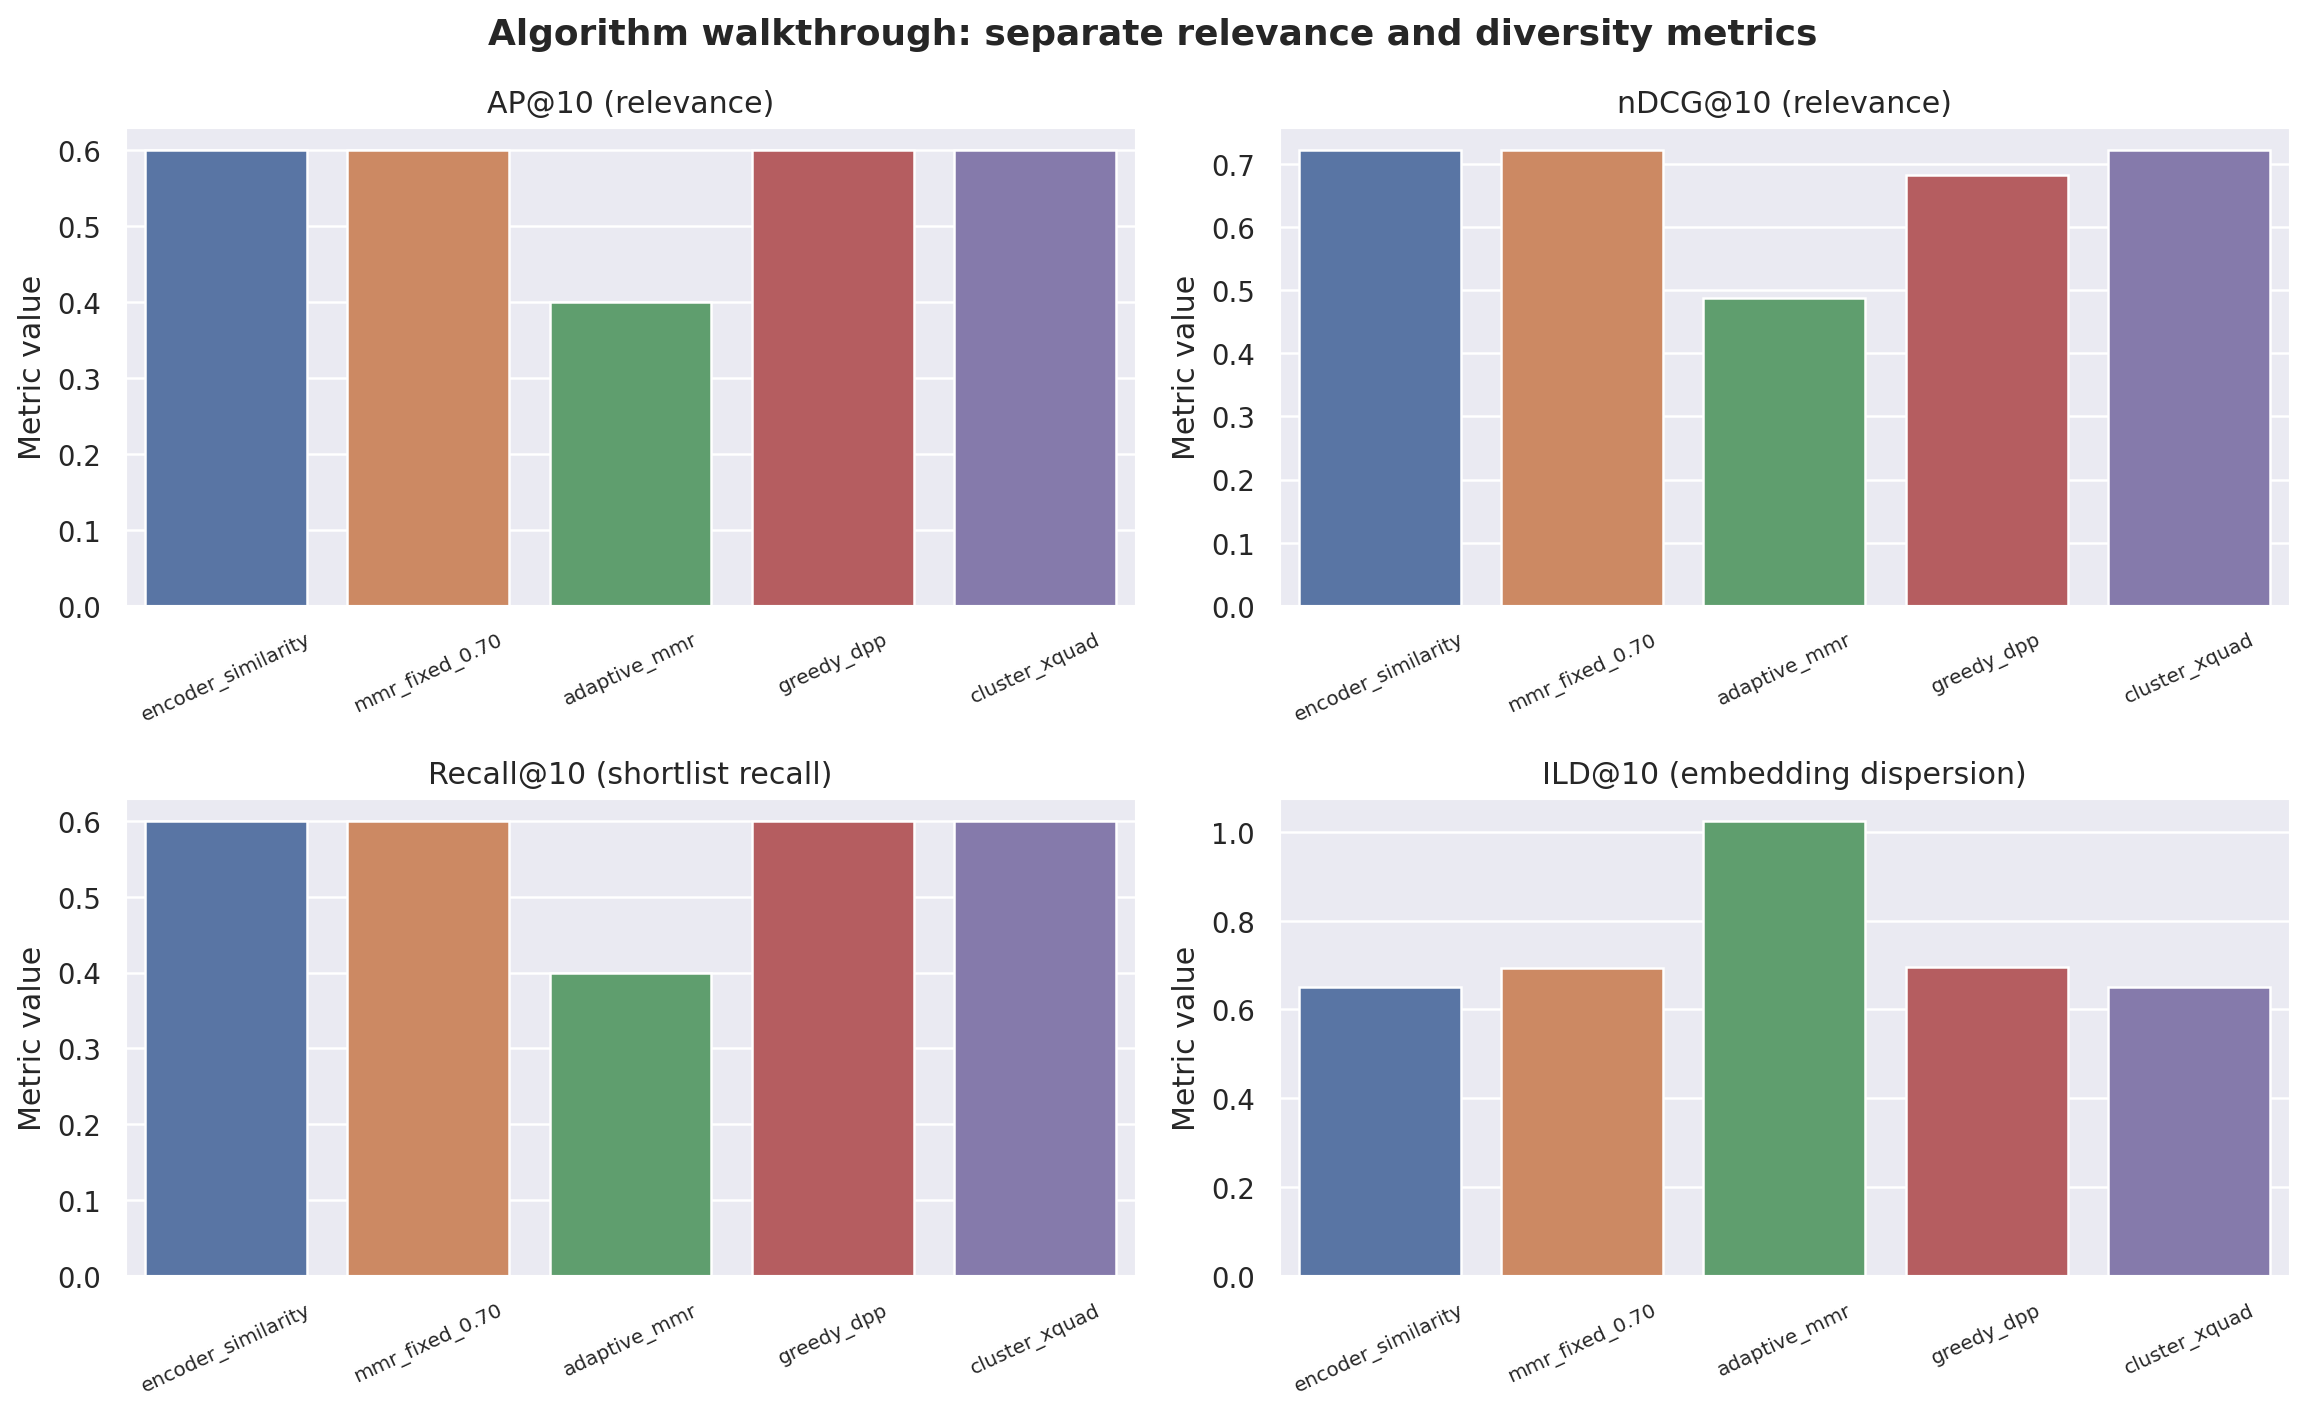

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="darkgrid", context="notebook", palette="deep")

metric_specs = [
    ("ap@10", "AP@10 (relevance)"),
    ("ndcg@10", "nDCG@10 (relevance)"),
    ("recall@10", "Recall@10 (shortlist recall)"),
    ("ild@10", "ILD@10 (embedding dispersion)"),
]
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
for axis, (metric_name, title) in zip(axes.flat, metric_specs):
    sns.barplot(data=metrics_table, x="method", y=metric_name, hue="method", legend=False, ax=axis)
    axis.set_title(title)
    axis.set_xlabel("")
    axis.set_ylabel("Metric value")
    axis.tick_params(axis="x", rotation=25, labelsize=8)
fig.suptitle("Algorithm walkthrough: separate relevance and diversity metrics", fontweight="bold")
fig.tight_layout()
figure_path = OUT / "figures" / "algorithm_walkthrough_metrics.png"
fig.savefig(figure_path, dpi=180, bbox_inches="tight")
plt.close(fig)
print("Saved figure:", figure_path)
from IPython.display import Image
display(Image(filename=str(figure_path)))

## 9. How to interpret this notebook

1. Verify each ranking contains unique candidate indices.
2. Check relevance metrics before treating a diversity increase as useful.
3. Look at the selected adaptive \(\lambda\) and ask whether the diagnostic signals justify it.
4. Compare all methods on the same fixed shortlist.
5. Use validation queries to choose a policy; reserve a held-out test split for the final report.
6. Replace pseudo-aspects with reliable attributes or query-intent labels if making claims about semantic aspect coverage.

**Next:** run `01_inquire_data_and_embeddings.ipynb` to build a real benchmark cache, then `02` and `03` for evaluation and uncertainty analysis.